# 41 微分方程模型

> **模块**：动态模型 ｜ **数据**：无（内置示例） ｜ **依赖**：matplotlib、numpy、pandas、sympy、scipy

## 1. 问题背景

微分方程描述连续变化的动态系统，常用于人口、传染病与物理过程建模。解析解难以求得时，用数值积分近似。

## 2. 学习目标

- 会从机理出发建立一阶或高阶方程
- 能用 `scipy.integrate` 求数值解
- 能分析平衡点及其稳定性

## 3. 环境与数据

- 依赖：matplotlib、numpy、pandas、sympy、scipy
- 数据：无（内置示例）

## 4. 方法与实现

### 4.1 微分方程模型

**用sympy和scipy**

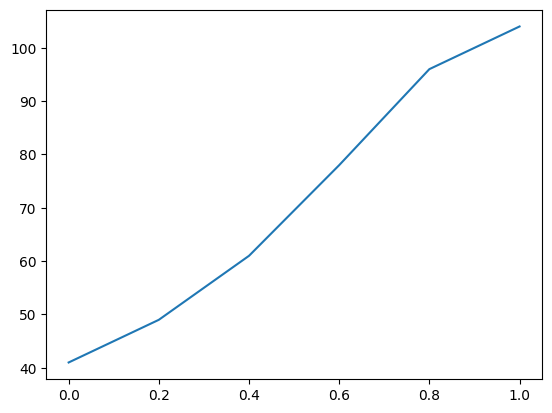

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

x0 = np.array([41, 49, 61, 78, 96, 104], dtype=float)  # 修正 np.float
plt.plot(np.linspace(0, 1, x0.shape[0]), x0)
plt.show()

lamb = np.array([x0[i] / x0[i+1] for i in range(x0.shape[0]-1)])
Theta = (np.exp(-2/(x0.shape[0]+1)), np.exp(2/(x0.shape[0]+2)))
OK = [i <= Theta[1] and i >= -Theta[0] for i in lamb]
x1 = np.array([x0[:i].sum() for i in range(1, x0.shape[0]+1)])
alpha1_x0 = np.array([x0[i] - x0[i-1] for i in range(1, x0.shape[0])])
z1 = np.array([(x1[i]+x1[i+1])/2 for i in range(x1.shape[0]-1)])
B = np.array(np.c_[-x0[1:], -z1, np.ones(z1.shape[0])])
Y = alpha1_x0
u = np.matmul(np.linalg.inv(np.matmul(B.T, B)), np.matmul(B.T, Y))
a1, a2, b = u[0], u[1], u[2]
x1_t = lambda k: (x0[0] - b/a) * np.exp(-a*k) + b/a

In [3]:
import sympy

sympy.init_printing()  # 加括号
t = sympy.Symbol('t')
a1_s, a2_s, b_s = sympy.symbols('a1 a2 b')  # 避免与数值变量重名也可
x1_f = sympy.Function('x1_t')  # 避免覆盖前面的 lambda

ode = sympy.Eq(x1_f(t).diff(t, t) + a1_s*x1_f(t).diff(t) + a2_s*x1_f(t), b_s)
ode_sol = sympy.dsolve(ode, x1_f(t))
print('得到带参符号解:', ode_sol)

x1_to_value = {
    x1_f(0): x1[0],
    x1_f(x1.shape[0]-1): x1[-1],
}
known_params = {a1_s, a2_s, b_s, t}
free_params = ode_sol.free_symbols - known_params
C_eqs = [
    sympy.Eq(ode_sol.lhs.subs(t, 0).subs(x1_to_value), ode_sol.rhs.subs(t, 0)),
    sympy.Eq(ode_sol.lhs.subs(t, x1.shape[0]-1).subs(x1_to_value), ode_sol.rhs.subs(t, x1.shape[0]-1)),
]
print('待定常数: ', free_params)
print('关于待定常数的多元方程组:', C_eqs, sep='\n')
sol_params = sympy.solve(C_eqs, free_params)
print('解得待定常数:', sol_params)
final_sol_eq = sympy.Eq(ode_sol.lhs, ode_sol.rhs.subs(sol_params))
print('最终解:', final_sol_eq.lhs, '=', final_sol_eq.rhs)

得到带参符号解: Eq(x1_t(t), C1*exp(t*(-a1 + sqrt(a1**2 - 4*a2))/2) + C2*exp(-t*(a1 + sqrt(a1**2 - 4*a2))/2) + b/a2)
待定常数:  {C1, C2}
关于待定常数的多元方程组:
[Eq(41.0, C1 + C2 + b/a2), Eq(429.0, C1*exp(-5*a1/2 + 5*sqrt(a1**2 - 4*a2)/2) + C2*exp(-5*a1/2 - 5*sqrt(a1**2 - 4*a2)/2) + b/a2)]
解得待定常数: {C1: -429.0*a2*exp(2.5*a1)*exp(2.5*sqrt(a1**2 - 4.0*a2))/(-2.0*a2*exp(5.0*sqrt(a1**2 - 4.0*a2)) + a2*exp(10.0*sqrt(a1**2 - 4.0*a2)) + a2) + 429.0*a2*exp(2.5*a1)*exp(7.5*sqrt(a1**2 - 4.0*a2))/(-2.0*a2*exp(5.0*sqrt(a1**2 - 4.0*a2)) + a2*exp(10.0*sqrt(a1**2 - 4.0*a2)) + a2) - 41.0*a2*exp(5.0*sqrt(a1**2 - 4.0*a2))/(-2.0*a2*exp(5.0*sqrt(a1**2 - 4.0*a2)) + a2*exp(10.0*sqrt(a1**2 - 4.0*a2)) + a2) + 41.0*a2/(-2.0*a2*exp(5.0*sqrt(a1**2 - 4.0*a2)) + a2*exp(10.0*sqrt(a1**2 - 4.0*a2)) + a2) + b*exp(2.5*a1)*exp(2.5*sqrt(a1**2 - 4.0*a2))/(-2.0*a2*exp(5.0*sqrt(a1**2 - 4.0*a2)) + a2*exp(10.0*sqrt(a1**2 - 4.0*a2)) + a2) - b*exp(2.5*a1)*exp(7.5*sqrt(a1**2 - 4.0*a2))/(-2.0*a2*exp(5.0*sqrt(a1**2 - 4.0*a2)) + a2*exp(10.0*sqrt(a1**2 - 

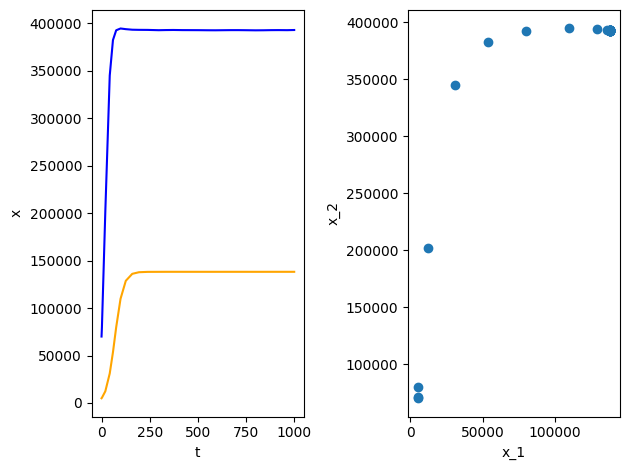

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import RK45

def funcs(t, x):
    dxdt = np.zeros(2)
    a = 1e-8
    dxdt[0] = 0.05*x[0]*(1-x[0]/150000) - a*x[0]*x[1]
    dxdt[1] = 0.08*x[1]*(1-x[1]/400000) - a*x[0]*x[1]
    return dxdt

t0 = 0
y0 = [5000, 70000]
t_bound = 1000
rk45 = RK45(fun=funcs, t0=t0, y0=y0, t_bound=t_bound)

t = [t0]
x = [[y0[0]], [y0[1]]]
while rk45.status == 'running':
    rk45.step()
    t.append(rk45.t)
    x[0].append(rk45.y[0])
    x[1].append(rk45.y[1])

plt.subplot(1, 2, 1)
plt.plot(t, x[0], color='orange')
plt.plot(t, x[1], color='b')
plt.xlabel('t')
plt.ylabel('x')
plt.subplot(1, 2, 2)
plt.scatter(x[0], x[1])
plt.xlabel('x_1')
plt.ylabel('x_2')
plt.tight_layout()
plt.show()

## 5. 小结

建模关键是厘清变量与变化率的因果关系；数值解需检查步长、刚性与初值敏感性。